In [ ]:
# === CABECALHO ACADEMICO (gerado por scripts/apply_header.py) ===
# Universidade Presbiteriana Mackenzie
# Disciplina: Inteligência Artificial
# Projeto: Previsão de desempenho de jogadores da NBA (pontos por jogo)
#
# INTEGRANTES DO GRUPO:
#   - Rodrigo Lucas Mascarenhas Leite Oliveira - TIA 10427925
#   - André Ihsan Ward - TIA 10425684
#
# ARQUIVO: notebooks/05_demo_artefato.ipynb
# SINTESE: Demonstração do artefato em jogos da temporada de teste.
#
# HISTORICO DE ALTERACOES:
#   data       | autor      | descricao
#   -----------|------------|-------------------------------------------
#   2026-11-15 | Rodrigo    | Versão inicial.
# === FIM DO CABECALHO ===


# 05 - Demonstração do artefato

`python -m src.predict` recebe um jogador e uma data (ou sorteia jogos do teste) e devolve: pontos previstos, intervalo de 80% e 90%, a baseline, a probabilidade de superar o próprio patamar recente e o que de fato aconteceu.

> Estimativa estatística de desempenho esportivo. Não é ferramenta nem recomendação de aposta: não há odds, valor esperado ou gestão de banca, e o "patamar recente" é a mediana do próprio jogador, não uma linha de mercado.

In [2]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 30)
TV = json.loads(Path("results/metrics/treino_validacao.json").read_text(encoding="utf-8"))
TF = json.loads(Path("results/metrics/test_final.json").read_text(encoding="utf-8"))

In [3]:
from src.predict import load_artifacts, predict_rows, render, AVISO
from src.modeling import load_dataset
df = load_dataset()
reg, clf, conf = load_artifacts()
amostra = df[df["split"] == "test"].sample(5, random_state=7).reset_index(drop=True)
res = predict_rows(amostra, reg, clf, conf)
for _, r in res.iterrows():
    print(render(r)); print()
print(AVISO)

Will Riley (WAS) x BOS  |  14/03/2026  |  split: test
------------------------------------------------------------------------------
  Pontos previstos ............ 13,1
  Intervalo de 80% ............ 4,7 a 21,6
  Intervalo de 90% ............ 2,5 a 23,8
  Baseline (média 5 jogos) .... 16,2
  Patamar recente (mediana 10)  16,0
  P(superar o patamar) ........ 26%
  Minutos médios (5 jogos) .... 31,2
------------------------------------------------------------------------------
  Real: 5 pontos  |  erro do modelo: -8,1  |  erro da baseline: -11,2
  Dentro do intervalo de 80%? sim  |  superou o patamar? não

Onyeka Okongwu (ATL) x PHI  |  14/12/2025  |  split: test
------------------------------------------------------------------------------
  Pontos previstos ............ 15,8
  Intervalo de 80% ............ 6,6 a 25,0
  Intervalo de 90% ............ 4,1 a 27,5
  Baseline (média 5 jogos) .... 15,0
  Patamar recente (mediana 10)  16,5
  P(superar o patamar) ........ 48%
  Minutos médios

## Um jogador ao longo da temporada de teste

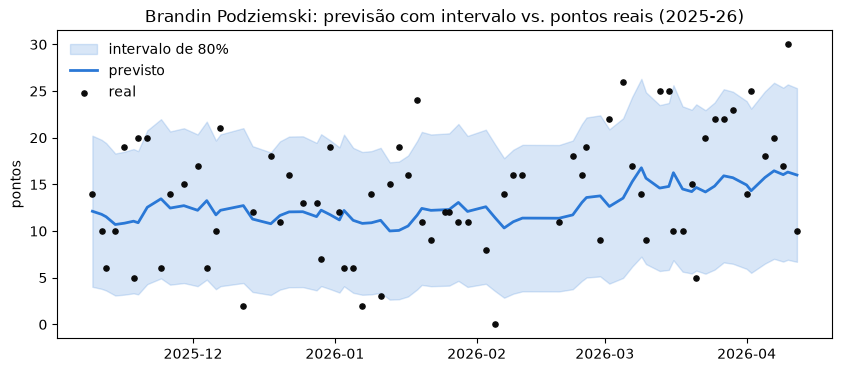

72 jogos; 78% dentro do intervalo de 80%


In [4]:
import matplotlib.pyplot as plt
nome = df[df["split"] == "test"]["PLAYER_NAME"].value_counts().index[0]
rows = df[(df["split"] == "test") & (df["PLAYER_NAME"] == nome)].sort_values("GAME_DATE").reset_index(drop=True)
r = predict_rows(rows, reg, clf, conf)
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(r["GAME_DATE"], r["ic80_inf"], r["ic80_sup"], color="#2a78d6", alpha=0.18, label="intervalo de 80%")
ax.plot(r["GAME_DATE"], r["previsto"], color="#2a78d6", linewidth=2, label="previsto")
ax.scatter(r["GAME_DATE"], r["y_pts"], color="#0b0b0b", s=14, zorder=3, label="real")
ax.set_title(f"{nome}: previsão com intervalo vs. pontos reais (2025-26)")
ax.set_ylabel("pontos"); ax.legend(loc="upper left", frameon=False); plt.show()
dentro = ((r["y_pts"] >= r["ic80_inf"]) & (r["y_pts"] <= r["ic80_sup"])).mean()
print(f"{len(r)} jogos; {dentro:.0%} dentro do intervalo de 80%")

## Escopo: o artefato recusa o que não sabe prever

In [5]:
import subprocess
out = subprocess.run([sys.executable, "-m", "src.predict", "--player", "jogador inexistente", "--date", "2026-01-15"], capture_output=True, text=True, encoding="utf-8")
print(out.stdout or out.stderr)

Jogo fora do escopo do modelo ou inexistente. O modelo só cobre jogadores de rotação (média >= 15 min nos 5 jogos anteriores) com 10+ jogos na temporada, em temporada regular de 2021-22 a 2025-26.

